# Chapitre 3 - Exercices 3.1 à 3.5

Ce notebook traite les cinq premiers exercices du chapitre 3, centrés sur le choix
entre modèles relationnel et document :

- **3.1** : choisir un modèle de données pour cinq applications (raisonnement) ;
- **3.2** : jointure multiple ou requêtes séparées ? Le seuil du produit cartésien
  (calcul et mesure) ;
- **3.3** : le coût d'un renommage dénormalisé et le risque d'incohérence (calcul et
  simulation) ;
- **3.4** : une relation plusieurs-à-plusieurs stockée des deux côtés, et sa
  réparation (mini-lab) ;
- **3.5** : migrer tout de suite ou à la lecture ? (calcul et simulation).

In [1]:
import json
import math
import sqlite3
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import datamodels as dm
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET, COLORS,
                           annotate_bars, finish, set_style, subtitle)

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 3)
pd.set_option("display.max_colwidth", 110)
rng = np.random.default_rng(0)
fmt = lambda v: f"{v:,.0f}".replace(",", " ")

## Exercice 3.1 : choisir un modèle de données

**Énoncé.** Pour chacune des applications suivantes, proposer un modèle de données
(relationnel, document, graphe, ou hybride) et justifier le choix par la **forme des
relations** et les **requêtes dominantes**. Signaler le principal piège du modèle retenu.

1. Un catalogue de produits de bricolage : 40 000 références dont les attributs varient
   selon la catégorie (une perceuse a une puissance et un mandrin, une peinture une
   couleur et un rendement), affichées une par une sur une fiche produit.
2. Un logiciel de facturation : clients, factures, lignes de facture, produits, avoirs,
   paiements, avec des états comptables mensuels.
3. Un blog : chaque article a quelques étiquettes et des commentaires ; certains articles
   viraux reçoivent des dizaines de milliers de commentaires.
4. La détection de fraude : retrouver des cercles de comptes bancaires qui partagent,
   directement ou par rebonds, des numéros de téléphone, des adresses ou des appareils.
5. Un tableur collaboratif de tâches que l'on réordonne par glisser-déposer.

**Rappels.** Arbre de relations un-à-plusieurs lu d'un bloc : document (cours 1).
Plusieurs-à-un et plusieurs-à-plusieurs : normalisation, relationnel (cours 2). Données
hétérogènes : schéma à la lecture (cours 3). Relations nombreuses et chemins de longueur
variable : graphe (cours 4). Sections *When to Use Which Model* et *Graph-Like Data Models*.

**Solution.**

*1. Catalogue* : **document**, ou colonne JSON dans une table relationnelle (hybride). Les
attributs sont hétérogènes (schéma à la lecture), chaque fiche est lue d'un bloc
(localité). Les champs communs (référence, prix, catégorie, stock) gagnent à être des
colonnes indexées. *Piège* : les filtres par attribut (« perceuses de plus de 800 W »)
exigent des index sur des valeurs imbriquées.

*2. Facturation* : **relationnel**. Les relations plusieurs-à-un (ligne -> produit,
facture -> client) dominent, les états mensuels sont des agrégations avec jointures, et
l'atomicité multi-enregistrements est indispensable (une facture et ses lignes ensemble).
*Piège* : dénormaliser le prix du produit dans la ligne **est ici voulu** (c'est le prix
historique au moment de la vente) : tout n'est pas à normaliser.

*3. Blog* : **document** pour l'article et ses étiquettes (arbre un-à-peu), mais les
commentaires dans une **collection séparée** référencée par l'identifiant de l'article :
des dizaines de milliers de commentaires feraient un document énorme, réécrit à chaque
ajout (cours 1, section 5).

*4. Fraude* : **graphe**. Comptes, téléphones, adresses, appareils sont des sommets ;
« utilise » est une arête ; un cercle est une **composante connexe**, de profondeur
inconnue à l'avance : c'est un parcours de longueur variable (`*0..` en Cypher, `WITH
RECURSIVE` en SQL).

*5. Liste réordonnable* : **document** (un tableau JSON garde l'ordre), ou relationnel avec
une astuce de tri (renumérotation, liste chaînée, indexation fractionnaire). *Piège* :
les modifications concurrentes de l'ordre par plusieurs utilisateurs.

**Vérification expérimentale** du cas 4 : générons 3 000 comptes qui partagent au hasard
des téléphones et des adresses, plantons un cercle de fraude (12 comptes reliés en chaîne
par des attributs partagés), et retrouvons-le comme composante connexe avec le
`PropertyGraph` du cours 4.

composante de acc100 : 14 comptes ; contient tout le cercle planté : True


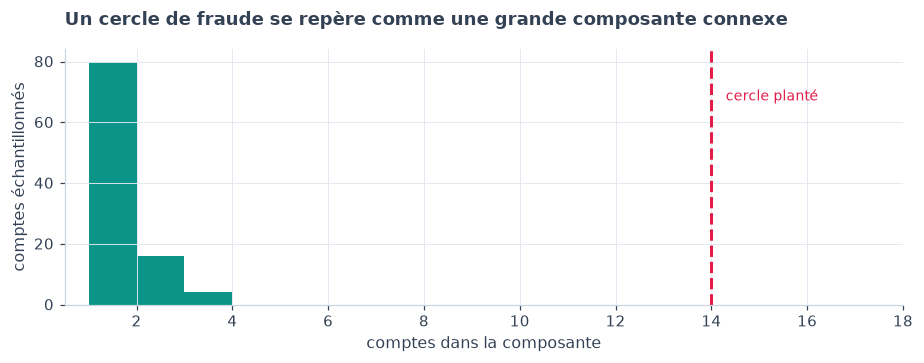

In [2]:
g = dm.PropertyGraph()
for a in range(3000):
    g.add_vertex(f"acc{a}", "Compte", name=f"acc{a}")
attrs = [f"tel{i}" for i in range(30_000)] + [f"adr{i}" for i in range(30_000)]
for a in attrs:
    g.add_vertex(a, "Attribut", name=a)
for a in range(3000):                                      # chaque compte : 1 téléphone et 1 adresse
    g.add_edge(f"acc{a}", f"tel{rng.integers(30_000)}", "UTILISE")
    g.add_edge(f"acc{a}", f"adr{rng.integers(30_000)}", "UTILISE")
cercle = [f"acc{a}" for a in range(100, 112)]
for k in range(len(cercle) - 1):                          # chaîne : chaque compte partage un appareil avec le suivant
    g.add_vertex(f"app{k}", "Attribut", name=f"app{k}")
    g.add_edge(cercle[k], f"app{k}", "UTILISE"); g.add_edge(cercle[k + 1], f"app{k}", "UTILISE")

def composante(g, v):
    """Parcours en largeur sur les arêtes UTILISE, dans les deux sens."""
    seen, front = {v}, [v]
    while front:
        nxt = []
        for x in front:
            for y in g.out(x, "UTILISE") + g.inn(x, "UTILISE"):
                if y not in seen:
                    seen.add(y); nxt.append(y)
        front = nxt
    return {x for x in seen if g.label(x) == "Compte"}

tailles = sorted((len(composante(g, f"acc{a}")) for a in range(0, 3000, 30)), reverse=True)
comp = composante(g, "acc100")
print(f"composante de acc100 : {len(comp)} comptes ; contient tout le cercle planté : {set(cercle) <= comp}")
fig, ax = plt.subplots(figsize=(8.5, 3.4))
ax.hist(tailles, bins=range(1, max(tailles) + 2), color=TEAL)
ax.axvline(len(comp), color=ROSE, ls="--"); ax.text(len(comp) + 0.3, ax.get_ylim()[1] * 0.8, "cercle planté", color=ROSE, fontsize=9)
ax.set_xlim(0.5, len(comp) + 4)
ax.set_xlabel("comptes dans la composante"); ax.set_ylabel("comptes échantillonnés")
ax.set_title("Un cercle de fraude se repère comme une grande composante connexe")
plt.tight_layout(); plt.show()

Les comptes ordinaires forment de petites composantes (quelques comptes qui partagent par
hasard un téléphone ou une adresse) ; le cercle planté ressort nettement. La requête
« tous les comptes reliés à acc100 par un nombre quelconque de rebonds » est triviale en
graphe, pénible dans les autres modèles.

> **À retenir.** On choisit un modèle d'après la forme des relations et les requêtes
> dominantes : arbre lu d'un bloc -> document ; plusieurs-à-un et agrégats -> relationnel ;
> connexions arbitraires et chemins de longueur variable -> graphe. Les hybrides sont
> souvent la bonne réponse.

## Exercice 3.2 : jointure multiple ou requêtes séparées ?

**Énoncé.** Un profil a $p$ postes, $e$ formations et $c$ coordonnées. On compare :

- **A** : 4 requêtes séparées, qui renvoient $1 + p + e + c$ lignes ;
- **B** : une jointure multiple (LEFT JOIN des trois tables filles), qui renvoie
  $\max(p,1)\max(e,1)\max(c,1)$ lignes ;
- **C** : un document JSON (1 requête, 1 ligne).

Le temps vu par le client vaut $q \cdot \text{RTT} + n \cdot t$, où $q$ est le nombre de
requêtes, $n$ le nombre de lignes, $t$ le coût de transfert et de décodage d'une ligne.

1. Avec RTT = 0,5 ms et $t$ = 0,01 ms, à partir de quand B devient-il plus lent que A ?
   Donner la condition générale.
2. Application : $c = 3$. Pour quels couples $(p, e)$ B perd-il ? Et avec RTT = 0,1 ms ?
3. Proposer une variante de B qui évite le produit cartésien en une seule requête.
4. Vérifier par la mesure du nombre de lignes sur SQLite, avec des profils aux listes
   longues.

**Rappels.** Le produit cartésien des listes indépendantes dans une jointure multiple,
le modèle `dm.round_trip_cost` (cours 1, section 4, section *The document data model for one-to-many relationships*).

**Solution.**

*1.* $T_A = 4\,\text{RTT} + (1+p+e+c)\,t$ et $T_B = \text{RTT} + pec\,t$ (listes non
vides). B perd quand $T_B > T_A$, soit
$$ (pec - 1 - p - e - c)\, t > 3\, \text{RTT} \iff pec - (1 + p + e + c) > 3\,\text{RTT}/t. $$
Avec 3 RTT / $t$ = 150 : B perd dès que le produit dépasse la somme de **150 lignes**.

*2.* Avec $c = 3$ : $3pe - p - e - 4 > 150$. Par exemple $p = e = 8$ donne
$192 - 20 = 172 > 150$ : B perd ; $p = e = 7$ donne $147 - 18 = 129$ : B gagne encore.
Avec RTT = 0,1 ms, le seuil tombe à 30 lignes : $p = e = 4$ suffit ($48 - 12 = 36$).
Plus le réseau est rapide, plus le produit cartésien pèse relativement.

*3.* Une **union** des trois sous-requêtes (`SELECT 'poste', ... UNION ALL SELECT
'formation', ...`) renvoie $p + e + c$ lignes en une requête ; ou bien des agrégats JSON
côté serveur (`json_group_array` dans SQLite), qui fabriquent... un document.

**Vérification** : carte du gagnant selon $(p, e)$, puis mesure sur SQLite avec des
profils jusqu'à 30 postes, et la variante par union.

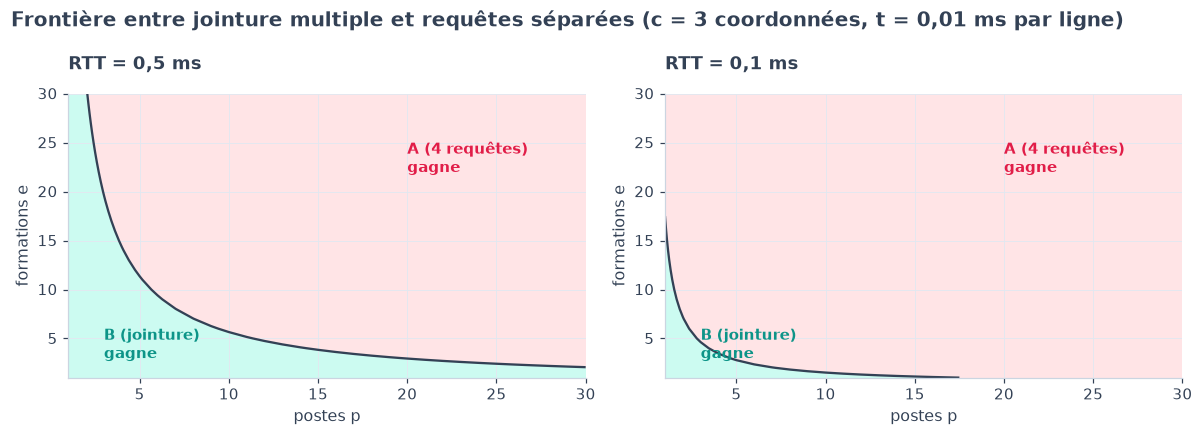

In [3]:
def gagnant(p, e, c, rtt, t=0.01):
    tA = 4 * rtt + (1 + p + e + c) * t
    tB = rtt + max(p, 1) * max(e, 1) * max(c, 1) * t
    return tB - tA

P = np.arange(1, 31)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, rtt in zip(axes, [0.5, 0.1]):
    Z = np.array([[gagnant(p, e, 3, rtt) for p in P] for e in P])
    ax.contourf(P, P, Z, levels=[-1e9, 0, 1e9], colors=[LIGHT[TEAL], LIGHT[ROSE]])
    ax.contour(P, P, Z, levels=[0], colors=[SLATE], linewidths=1.5)
    ax.text(3, 3, "B (jointure)\ngagne", color=TEAL, fontsize=10, fontweight="bold")
    ax.text(20, 22, "A (4 requêtes)\ngagne", color=ROSE, fontsize=10, fontweight="bold")
    ax.set_xlabel("postes p"); ax.set_ylabel("formations e"); ax.set_title(f"RTT = {rtt:g} ms".replace(".", ","))
finish(fig, "Frontière entre jointure multiple et requêtes séparées (c = 3 coordonnées, t = 0,01 ms par ligne)")

In [4]:
profs = dm.make_profiles(300, seed=5, max_positions=30)
for p in profs:                                            # des formations plus nombreuses aussi
    p["education"] = p["education"] * 3
con = sqlite3.connect(":memory:")
dm.create_relational(con, profs)
cc = dm.CountingConnection(con)
UNION_SQL = """
SELECT 'poste', job_title, start FROM positions WHERE user_id = :u
UNION ALL SELECT 'formation', school_name, start FROM education WHERE user_id = :u
UNION ALL SELECT 'contact', kind, value FROM contact_info WHERE user_id = :u"""
rows = []
for p in profs[:200]:
    u = p["user_id"]
    cc.reset(); dm.get_profile_join(cc, u); n_join = cc.rows
    n_union = len(con.execute(UNION_SQL, {"u": u}).fetchall())
    pp, ee, c3 = len(p["positions"]), len(p["education"]), len(p["contact_info"])
    assert n_join == max(pp, 1) * max(ee, 1) * max(c3, 1) and n_union == pp + ee + c3
    rows.append({"p": pp, "e": ee, "c": c3, "lignes jointure": n_join, "lignes union": n_union})
mes = pd.DataFrame(rows)
mes["B perd (RTT 0,5 ms)"] = [gagnant(r.p, r.e, r.c, 0.5) > 0 for r in mes.itertuples()]
print(f"formule vérifiée sur {len(mes)} profils ; la jointure renvoie jusqu'à {mes['lignes jointure'].max()} lignes "
      f"(union : {mes['lignes union'].max()}) ; B perd pour {mes['B perd (RTT 0,5 ms)'].mean():.0%} des profils".replace(".", ","))
mes.sort_values("lignes jointure", ascending=False).head(4)

formule vérifiée sur 200 profils ; la jointure renvoie jusqu'à 810 lignes (union : 42) ; B perd pour 23% des profils


,p,e,c,lignes jointure,lignes union,"B perd (RTT 0,5 ms)"
42,30,9,3,810,42,True
156,22,9,3,594,34,True
130,21,9,3,567,33,True
50,21,9,3,567,33,True


La mesure confirme le produit $pec$ pour la jointure et la somme $p + e + c$ pour l'union.
Avec des listes longues, la jointure multiple transporte des centaines de lignes inutiles.

> **À retenir.** Une jointure multiple sur des listes indépendantes coûte $pec$ lignes ;
> elle bat les requêtes séparées tant que $pec - (1+p+e+c) < 3\,\text{RTT}/t$. Une union
> (ou un agrégat JSON) donne une seule requête sans produit cartésien.

## Exercice 3.3 : le coût d'un renommage dénormalisé

**Énoncé.** 200 organisations et 70 000 postes ; la popularité des organisations suit une
loi de Zipf d'exposant 1,1. Le nom de l'organisation est dénormalisé dans chaque poste.

1. Une organisation est renommée. Combien de lignes faut-il réécrire **en moyenne** si
   l'organisation renommée est tirée (a) uniformément, (b) proportionnellement à sa
   popularité ? Pourquoi (b) est-il plus réaliste pour certaines mises à jour (un logo
   changé, un compteur...) ?
2. Sans transaction, chaque écriture a une probabilité $q = 10^{-5}$ d'être la dernière
   avant une panne. Quelle est la probabilité qu'un renommage de l'organisation la plus
   populaire laisse la base **incohérente** ?
3. Quel surcoût d'espace la dénormalisation représente-t-elle si un nom fait en moyenne
   12 octets et un identifiant 4 octets ?

**Rappels.** Coût d'une mise à jour dénormalisée = nombre de copies ; panne au milieu
d'une mise à jour multiple (cours 2, section 2, section *Trade-offs of normalization*).

**Solution.**

*1.* Notons $w_i = i^{-1{,}1} / H$ la part des postes de l'organisation de rang $i$, avec
$H = \sum_{j=1}^{200} j^{-1{,}1} \approx 4{,}7$. (a) Tirage uniforme : en moyenne
$70\,000 / 200 = 350$ lignes. (b) Tirage proportionnel : $\mathbb{E} = 70\,000 \sum_i w_i^2$,
dominé par les grosses organisations ; numériquement $\sum w_i^2 \approx 0{,}067$, soit
environ **4 700** lignes, treize fois plus. Quand la mise à jour suit l'activité (compteurs, contenus
consultés), ce sont les entités populaires qui changent le plus : le pire cas devient le
cas courant.

*2.* L'organisation de rang 1 a $70\,000 \times w_1 \approx 70\,000 / 4{,}7 \approx 15\,000$
copies. Probabilité d'au moins une panne au cours des $k$ écritures :
$1 - (1 - q)^k \approx 1 - e^{-qk} = 1 - e^{-0{,}15} \approx 14\,\%$.

*3.* Dénormalisé : 12 octets par poste ; normalisé : 4 octets par poste + 200 × 12 octets.
Surcoût ≈ $70\,000 \times 8$ ≈ 560 Ko, soit **trois fois** plus d'espace pour cette
colonne.

**Vérification** : calcul exact sur la distribution, puis simulation de 20 000 renommages
de l'organisation la plus populaire avec pannes aléatoires.

H = 4.70 ; uniforme : 350 lignes ; proportionnel : 4721 lignes ; rang 1 : 14897 copies


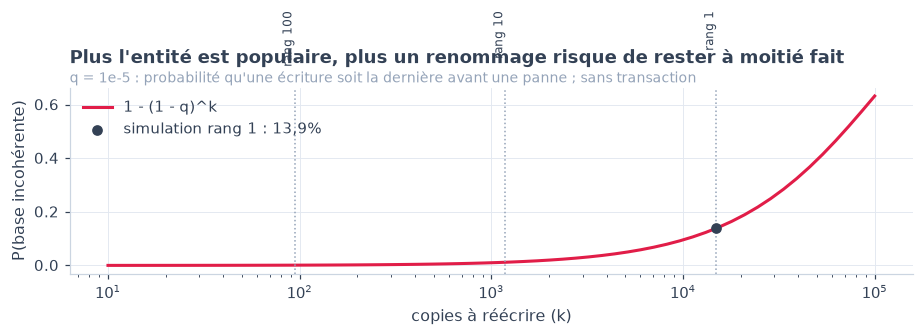

In [5]:
ranks = np.arange(1, 201)
w = ranks ** -1.1; H = w.sum(); w /= H
copies = 70_000 * w
print(f"H = {H:.2f} ; uniforme : {copies.mean():.0f} lignes ; proportionnel : {(copies * w).sum():.0f} lignes ; "
      f"rang 1 : {copies[0]:.0f} copies")
q, k = 1e-5, int(round(copies[0]))
sim = rng.random((20_000,)) < 1 - (1 - q) ** k              # au moins une panne parmi k écritures
fig, ax = plt.subplots(figsize=(8.5, 3.6))
ks = np.logspace(1, 5, 60)
ax.semilogx(ks, 1 - (1 - q) ** ks, color=ROSE, lw=2, label="1 - (1 - q)^k")
ax.scatter([k], [sim.mean()], color=SLATE, zorder=5, label=f"simulation rang 1 : {sim.mean():.1%}".replace(".", ","))
for r in [1, 10, 100]:
    ax.axvline(copies[r - 1], color=GRAY, ls=":", lw=1)
    ax.text(copies[r - 1], 0.95, f"rang {r}", rotation=90, va="top", ha="right", fontsize=8, color=SLATE)
ax.set_xlabel("copies à réécrire (k)"); ax.set_ylabel("P(base incohérente)")
ax.set_title("Plus l'entité est populaire, plus un renommage risque de rester à moitié fait")
subtitle(ax, "q = 1e-5 : probabilité qu'une écriture soit la dernière avant une panne ; sans transaction")
ax.legend(); plt.tight_layout(); plt.show()

Calcul et simulation concordent : environ 14 % des renommages de l'organisation la plus
populaire laisseraient deux noms coexister. Avec une transaction atomique, ce risque
disparaît (chapitre 8).

> **À retenir.** Le coût moyen d'une mise à jour dénormalisée dépend de la distribution
> des mises à jour : si elles suivent la popularité, c'est la queue de distribution qui
> domine. La probabilité d'incohérence sans transaction croît comme $1 - e^{-qk}$.

## Exercice 3.4 : une relation stockée des deux côtés, et sa réparation

**Énoncé.** Une application documents stocke la relation « a travaillé pour » des deux
côtés : chaque profil liste ses `org_ids`, chaque organisation ses `user_ids`. Chaque
ajout écrit d'abord le profil, puis l'organisation ; une panne entre les deux survient
avec probabilité $p$.

1. Après $N$ ajouts, combien de relations incohérentes attend-on ? Application :
   $N = 10^6$ par jour, $p = 10^{-4}$.
2. Écrire une tâche de **réconciliation** qui détecte et répare les incohérences en
   prenant le profil comme source de vérité. Quel est son coût ?
3. Comparer avec la représentation normalisée (une seule table d'association indexée
   sur ses deux colonnes) : que coûte la même question « qui a travaillé chez X » ?

**Rappels.** Plusieurs-à-plusieurs, références des deux côtés = dénormalisation ;
index secondaires sur les deux colonnes d'une table d'association (cours 2, section 3,
section *Many-to-One and Many-to-Many Relationships*).

**Solution.**

*1.* Chaque ajout produit une incohérence avec probabilité $p$ (si la relation est
nouvelle) : espérance $Np$, soit **100 incohérences par jour**, qui s'accumulent tant que
rien ne les répare.

*2.* Réconciliation : construire l'ensemble des paires vues depuis les profils, celui vu
depuis les organisations, et corriger la différence symétrique. Coût : un parcours
complet des deux collections, $O(\text{nombre de relations})$, à lancer périodiquement
(c'est une forme d'**anti-entropie**, que l'on retrouvera avec la réplication au chapitre
6).

*3.* Normalisé : la relation n'existe qu'une fois ; « qui a travaillé chez X » est une
recherche dans l'index sur `org_id`, en $O(\log n + \text{réponses})$, et aucune
incohérence n'est possible.

In [6]:
def run(n_ops, p, seed):
    r = np.random.default_rng(seed)
    user_orgs, org_users = {}, {}
    for _ in range(n_ops):
        u, o = int(r.integers(0, 5000)), int(r.integers(0, 300))
        user_orgs.setdefault(u, set()).add(o)
        if r.random() >= p:
            org_users.setdefault(o, set()).add(u)
    return user_orgs, org_users

def reconcile(user_orgs, org_users):
    """Source de vérité : les profils. Renvoie (ajouts, suppressions) appliqués côté organisations."""
    vrai = {(u, o) for u, os in user_orgs.items() for o in os}
    vu = {(u, o) for o, us in org_users.items() for u in us}
    for u, o in vrai - vu:
        org_users.setdefault(o, set()).add(u)
    for u, o in vu - vrai:
        org_users[o].discard(u)
    return len(vrai - vu), len(vu - vrai)

rows = []
for p in [1e-4, 1e-3, 1e-2]:
    uo, ou = run(200_000, p, seed=1)
    t0 = time.perf_counter(); add, rem = reconcile(uo, ou); dt = time.perf_counter() - t0
    assert reconcile(uo, ou) == (0, 0)                      # après réparation : plus rien à faire
    rows.append({"p": p, "attendu N·p": 200_000 * p, "incohérences trouvées": add, "réconciliation (ms)": dt * 1e3})
pd.DataFrame(rows)

,p,attendu N·p,incohérences trouvées,réconciliation (ms)
0,1.000e-04,20.0,20,147.386
1,1.000e-03,200.0,161,156.880
2,1.000e-02,2000.0,1745,149.064


Le nombre d'incohérences trouvées colle à $Np$ (un peu moins, car certains ajouts
répètent une relation déjà présente des deux côtés). La réconciliation les répare toutes,
au prix d'un parcours complet ; en normalisé, il n'y aurait rien à réparer.

> **À retenir.** Une relation stockée deux fois diverge d'environ $Np$ paires après $N$
> écritures non atomiques ; on peut la réparer par réconciliation périodique, mais la
> représentation normalisée indexée des deux côtés évite le problème.

## Exercice 3.5 : migrer tout de suite ou à la lecture ?

**Énoncé.** Une collection de $N = 50$ millions de profils doit passer d'un champ `name`
à deux champs `first_name` / `last_name`.

- **Migration immédiate** (schéma à l'écriture) : un processus réécrit les lignes à
  20 000 lignes/s, limité à 25 % du temps pour ne pas gêner la production.
- **Migration paresseuse** (schéma à la lecture) : un profil est converti quand il est
  **modifié** ; chaque jour, 2 % des profils sont modifiés (au hasard).

1. Combien de temps dure la migration immédiate ?
2. En migration paresseuse, quelle fraction de profils reste à l'ancien format après
   $t$ jours ? Combien de jours pour atteindre 99 % de profils convertis ?
3. On combine : migration paresseuse, plus une tâche de fond qui convertit 1 million de
   profils par jour (pris parmi les non convertis). Quand la migration est-elle finie ?

**Rappels.** Schéma à l'écriture : la migration réécrit chaque ligne ; schéma à la
lecture : tout le code lecteur gère les anciens formats (cours 3, section 2, section
*Schema flexibility in the document model*).

**Solution.**

*1.* Débit effectif $20\,000 \times 0{,}25 = 5\,000$ lignes/s : $5 \cdot 10^7 / 5\,000 =
10\,000$ s, soit environ **2 h 47**.

*2.* Chaque jour, un profil non converti a 2 % de chances d'être modifié : la fraction
restante est $(0{,}98)^t$. 99 % convertis $\iff 0{,}98^t \le 0{,}01 \iff t \ge
\ln 0{,}01 / \ln 0{,}98 \approx$ **228 jours**. Et il restera toujours quelques profils
jamais modifiés : le code de lecture tolérant devra rester en place.

*3.* Notons $R_t$ le nombre de profils restants. Chaque jour :
$R_{t+1} = 0{,}98\,R_t - 10^6$ (tant que positif). Cette récurrence affine a pour point
fixe $R^* = -10^6/0{,}02 = -5 \cdot 10^7$, d'où $R_t = (N - R^*)\,0{,}98^t + R^* =
10^8 \times 0{,}98^t - 5 \cdot 10^7$, qui s'annule pour $0{,}98^t = 1/2$, soit
$t \approx 34{,}3$ : la migration est finie en **35 jours**, au lieu de jamais.

1. migration immédiate : 10000 s = 2.78 h
2. 99 % convertis après 228 jours


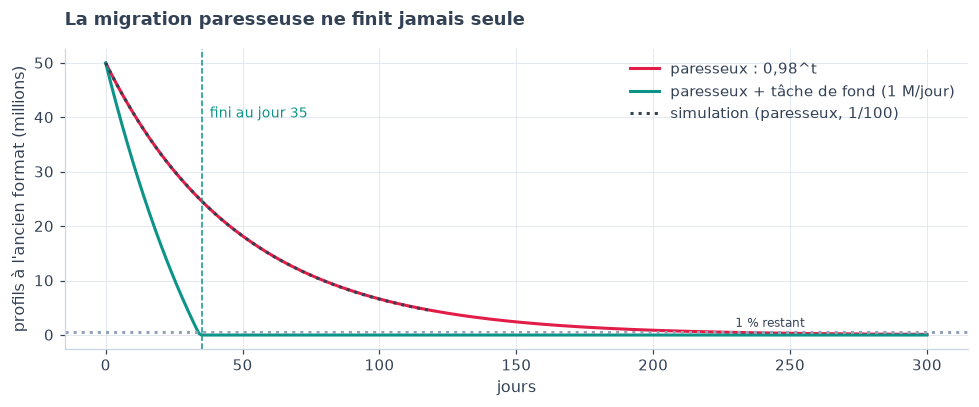

In [7]:
N = 50e6
print(f"1. migration immédiate : {N / (20_000 * 0.25):.0f} s = {N / 5000 / 3600:.2f} h")
print(f"2. 99 % convertis après {math.log(0.01) / math.log(0.98):.0f} jours")
jours = np.arange(0, 301)
paresseux = N * 0.98 ** jours
R, mixte = N, []
for t in jours:
    mixte.append(R)
    R = max(0.0, 0.98 * R - 1e6)
fin = int(np.argmax(np.array(mixte) == 0))
# vérification par simulation stochastique sur 500 000 profils (échelle 1/100)
n_sim = 500_000
old = np.ones(n_sim, bool); sim_rest = []
for t in jours[:120]:
    sim_rest.append(old.sum() * 100)
    old &= rng.random(n_sim) >= 0.02
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(jours, paresseux / 1e6, color=ROSE, label="paresseux : 0,98^t")
ax.plot(jours, np.array(mixte) / 1e6, color=TEAL, label="paresseux + tâche de fond (1 M/jour)")
ax.plot(jours[:120], np.array(sim_rest) / 1e6, color=SLATE, ls=":", label="simulation (paresseux, 1/100)")
ax.axvline(fin, color=TEAL, ls="--", lw=1); ax.text(fin + 3, 40, f"fini au jour {fin}", color=TEAL, fontsize=9)
ax.axhline(0.5, color=GRAY, ls=":"); ax.text(230, 1.5, "1 % restant", fontsize=8, color=SLATE)
ax.set_xlabel("jours"); ax.set_ylabel("profils à l'ancien format (millions)")
ax.set_title("La migration paresseuse ne finit jamais seule")
ax.legend(); plt.tight_layout(); plt.show()

La migration immédiate est courte en durée mais lourde pour la base (toutes les lignes
réécrites, beaucoup de journal) ; la migration paresseuse ne coûte presque rien mais
traîne indéfiniment, et le code lecteur doit gérer les deux formats aussi longtemps. La
combinaison (conversion à la volée **et** tâche de fond bornée en débit) est ce que font
les outils de migration en ligne.

> **À retenir.** Migration immédiate : durée $N / \text{débit}$, coût concentré.
> Migration paresseuse : décroissance géométrique $(1-u)^t$, jamais terminée. Une tâche
> de fond qui convertit les retardataires borne la durée.